In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [24]:
# Project directories

BASE_DIR = Path("..")

DATA_DIR = BASE_DIR / "data" / "cleaned"

CHART_DIR = BASE_DIR / "outputs" / "charts"

DASHBOARD_DIR = BASE_DIR / "outputs" / "dashboard"

REPORT_DIR = BASE_DIR / "outputs" / "reports"


# Create output directories if they do not exist

CHART_DIR.mkdir(parents=True, exist_ok=True)
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project paths configured successfully!")
print("Data directory:", DATA_DIR.resolve())

Project paths configured successfully!
Data directory: C:\Users\varat\Data-Science-Week1-Assignment\Task-3_visualization\data\cleaned


In [25]:
customers = pd.read_csv(DATA_DIR / "customers.csv")

geolocation = pd.read_csv(DATA_DIR / "geolocation.csv")

order_items = pd.read_csv(DATA_DIR / "order_items.csv")

payments = pd.read_csv(DATA_DIR / "payments.csv")

reviews = pd.read_csv(DATA_DIR / "reviews.csv")

orders = pd.read_csv(DATA_DIR / "orders.csv")

products = pd.read_csv(DATA_DIR / "products.csv")

sellers = pd.read_csv(DATA_DIR / "sellers.csv")

category_translation = pd.read_csv(
    DATA_DIR / "category_translation.csv"
)

print("All cleaned datasets loaded successfully!")

All cleaned datasets loaded successfully!


In [26]:
datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Orders": orders,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

overview = []

for name, df in datasets.items():

    overview.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum()
    })

dataset_overview = pd.DataFrame(overview)

display(dataset_overview)

,Dataset,Rows,Columns,Missing Values
0,Customers,99441,5,0
1,Geolocation,738332,5,0
2,Order Items,112650,7,0
3,Payments,103886,5,0
4,Reviews,99224,7,145903
5,Orders,99441,8,4908
6,Products,32951,16,1838
7,Sellers,3095,4,0
8,Category Translation,71,2,0


In [27]:
# Convert order purchase timestamp into datetime

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Keep delivered orders for delivered-sales visualizations

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Merge order items with delivered orders

sales_data = order_items.merge(
    delivered_orders[
        ["order_id", "customer_id", "order_purchase_timestamp"]
    ],
    on="order_id",
    how="inner"
)

# Merge product details

sales_data = sales_data.merge(
    products[
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left"
)

# Merge English category translations

sales_data = sales_data.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Create readable category names

sales_data["category_name"] = (
    sales_data["product_category_name_english"]
    .fillna(sales_data["product_category_name"])
    .fillna("Unknown")
)

# Create revenue column

sales_data["revenue"] = pd.to_numeric(
    sales_data["price"],
    errors="coerce"
).fillna(0)

# Create month column

sales_data["month"] = (
    sales_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

print("Sales data prepared successfully!")

display(sales_data.head())

Sales data prepared successfully!


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,product_category_name,product_category_name_english,category_name,revenue,month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,cool_stuff,cool_stuff,cool_stuff,58.90,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,pet_shop,pet_shop,pet_shop,239.90,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,moveis_decoracao,furniture_decor,furniture_decor,199.00,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,perfumaria,perfumery,perfumery,12.99,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,ferramentas_jardim,garden_tools,garden_tools,199.90,2017-02


In [28]:
total_revenue = sales_data["revenue"].sum()

total_orders = sales_data["order_id"].nunique()

total_units_sold = len(sales_data)

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0 else 0
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold"
    ],

    "Value": [
        round(total_revenue, 2),
        total_orders,
        round(average_order_value, 2),
        total_units_sold
    ]
})

display(kpi_summary)

kpi_summary.to_csv(
    REPORT_DIR / "visualization_kpi_summary.csv",
    index=False
)

,KPI,Value
0,Total Revenue,13221498.11
1,Total Orders,96478.00
2,Average Order Value,137.04
3,Total Units Sold,110197.00


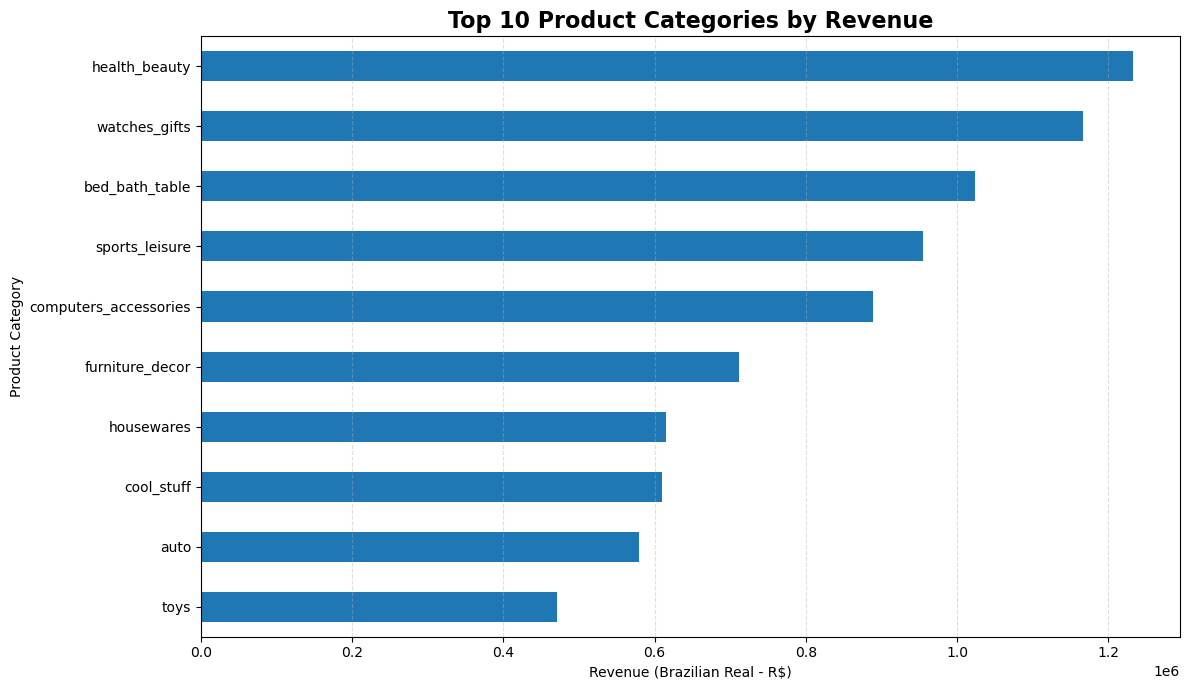

In [29]:
category_revenue = (
    sales_data.groupby("category_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))

category_revenue.sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 10 Product Categories by Revenue",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Revenue (Brazilian Real - R$)")
plt.ylabel("Product Category")

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "top_10_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
top_category = category_revenue.idxmax()

top_category_revenue = category_revenue.max()

print("BAR CHART – BUSINESS INTERPRETATION")

print(
    f"The highest revenue-generating category is "
    f"{top_category}, with revenue of R$ "
    f"{top_category_revenue:,.2f}."
)

print(
    "The chart compares the ten highest revenue-generating "
    "product categories."
)

print(
    "Business Recommendation: Review inventory availability "
    "and marketing performance for the leading categories."
)

BAR CHART – BUSINESS INTERPRETATION
The highest revenue-generating category is health_beauty, with revenue of R$ 1,233,131.72.
The chart compares the ten highest revenue-generating product categories.
Business Recommendation: Review inventory availability and marketing performance for the leading categories.


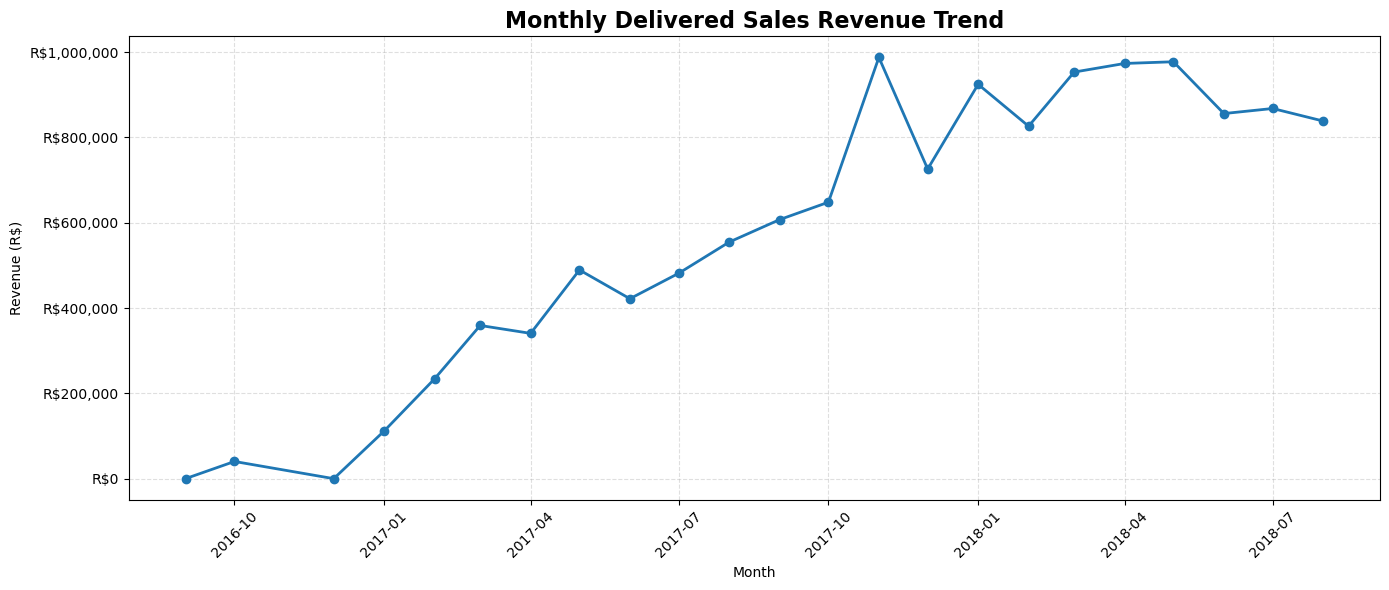

In [31]:
monthly_sales = (
    sales_data.dropna(subset=["month"])
    .groupby("month")["revenue"]
    .sum()
    .sort_index()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Delivered Sales Revenue Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")

plt.ylabel("Revenue (R$)")

plt.xticks(rotation=45)

plt.grid(True, linestyle="--", alpha=0.4)

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("R${x:,.0f}")
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
highest_month = monthly_sales.idxmax()

highest_month_revenue = monthly_sales.max()

lowest_month = monthly_sales.idxmin()

lowest_month_revenue = monthly_sales.min()

print("LINE CHART – BUSINESS INTERPRETATION")

print(
    f"The highest monthly delivered revenue was recorded in "
    f"{highest_month.strftime('%B %Y')}."
)

print(
    f"Revenue during that month was R$ "
    f"{highest_month_revenue:,.2f}."
)

print(
    f"The lowest monthly revenue was recorded in "
    f"{lowest_month.strftime('%B %Y')}, with R$ "
    f"{lowest_month_revenue:,.2f}."
)

print(
    "Business Recommendation: Investigate monthly peaks and "
    "declines alongside promotions, order volume and demand."
)

print(
    "Note: The first and last months of the dataset may be partial months."
)

LINE CHART – BUSINESS INTERPRETATION
The highest monthly delivered revenue was recorded in November 2017.
Revenue during that month was R$ 987,765.37.
The lowest monthly revenue was recorded in December 2016, with R$ 10.90.
Business Recommendation: Investigate monthly peaks and declines alongside promotions, order volume and demand.
Note: The first and last months of the dataset may be partial months.


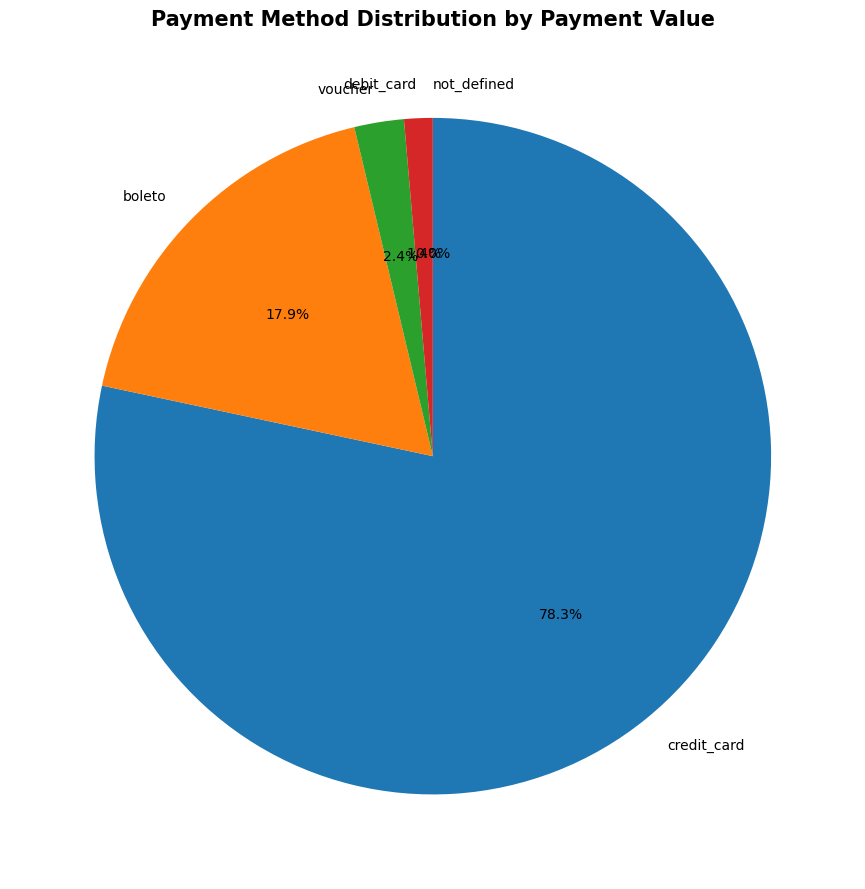

In [33]:
payment_data = payments.copy()

payment_data["payment_value"] = pd.to_numeric(
    payment_data["payment_value"],
    errors="coerce"
).fillna(0)

payment_distribution = (
    payment_data.groupby("payment_type")["payment_value"]
    .sum()
    .sort_values(ascending=False)
)

# Exclude missing or unknown payment types from the chart

payment_distribution = payment_distribution[
    payment_distribution.index.notna()
]

plt.figure(figsize=(9, 9))

plt.pie(
    payment_distribution.values,
    labels=payment_distribution.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False
)

plt.title(
    "Payment Method Distribution by Payment Value",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "payment_method_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
top_payment_method = payment_distribution.idxmax()

top_payment_value = payment_distribution.max()

total_payment_value = payment_distribution.sum()

top_payment_percentage = (
    top_payment_value / total_payment_value * 100
    if total_payment_value > 0 else 0
)

print("PIE CHART – BUSINESS INTERPRETATION")

print(
    f"{top_payment_method} is the highest payment method "
    f"by recorded payment value."
)

print(
    f"It contributes approximately "
    f"{top_payment_percentage:.2f}% of the total "
    f"payment value represented in this chart."
)

print(
    "Business Recommendation: Monitor payment preferences "
    "to improve checkout experience."
)

print(
    "Note: Payment records include all order statuses, "
    "not only delivered orders."
)

PIE CHART – BUSINESS INTERPRETATION
credit_card is the highest payment method by recorded payment value.
It contributes approximately 78.34% of the total payment value represented in this chart.
Business Recommendation: Monitor payment preferences to improve checkout experience.
Note: Payment records include all order statuses, not only delivered orders.


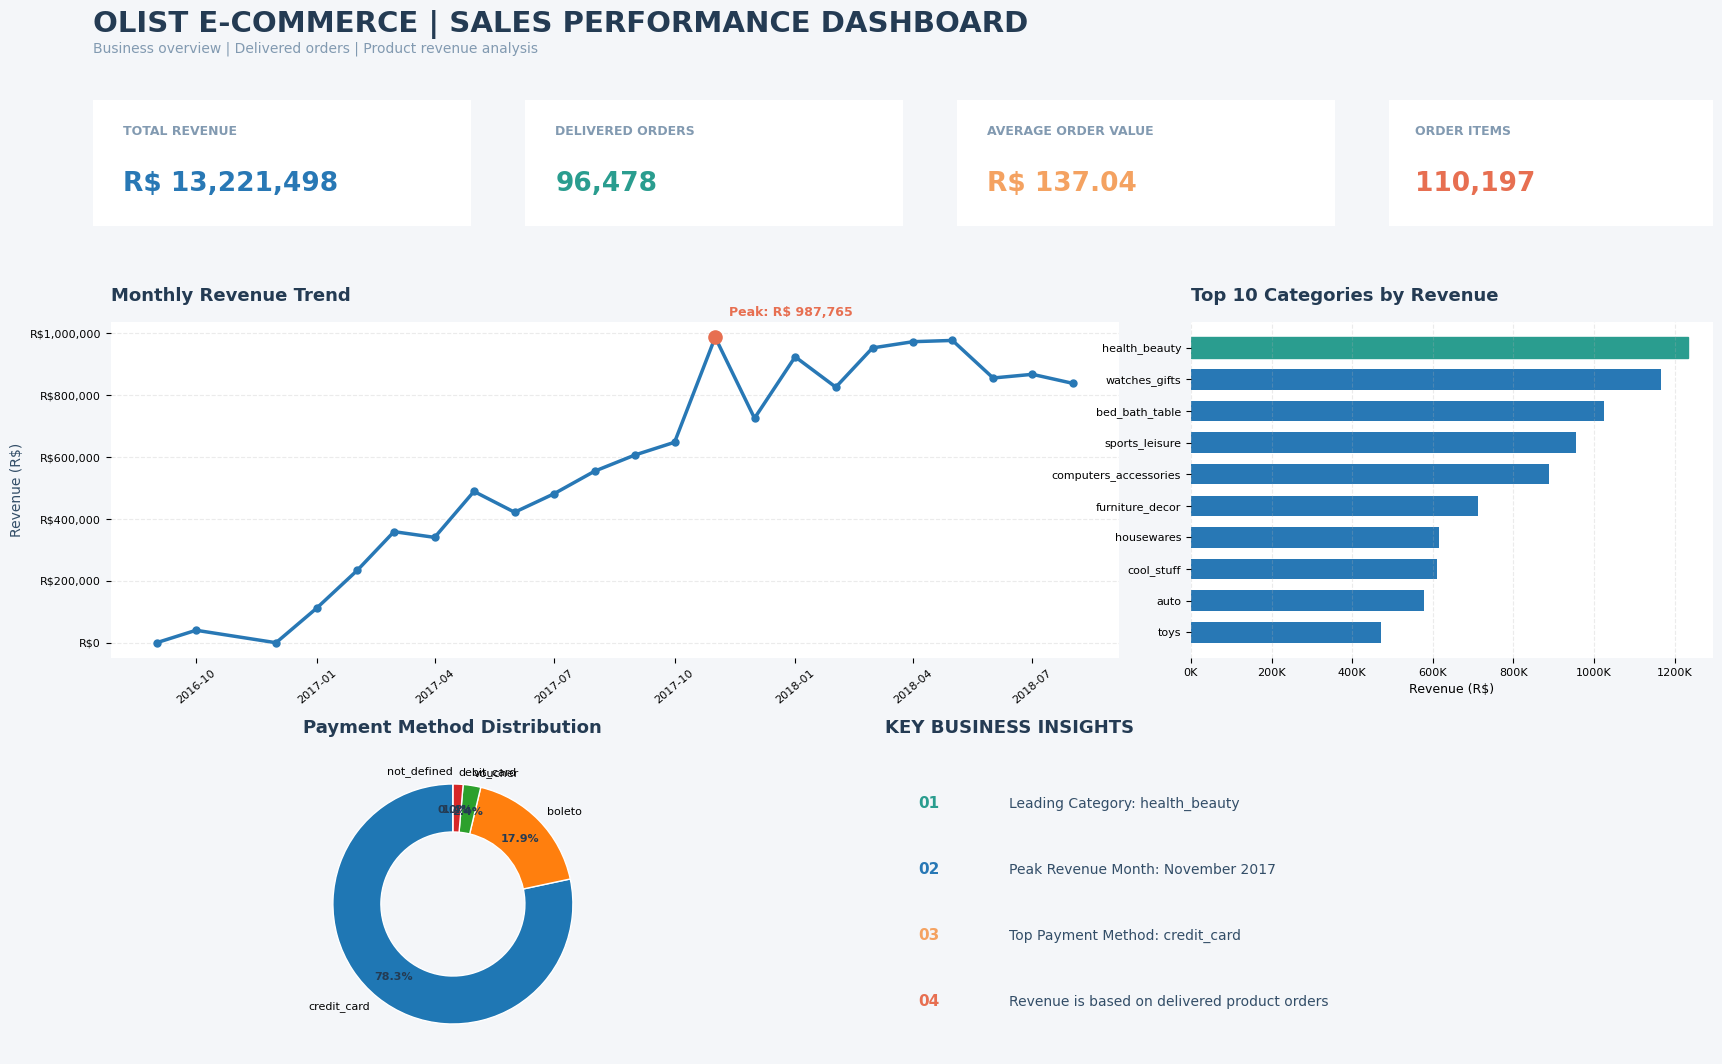

In [43]:





BG_COLOR = "#F4F6F9"
CARD_COLOR = "#FFFFFF"
PRIMARY = "#243B53"
BLUE = "#2878B5"
GREEN = "#2A9D8F"
ORANGE = "#F4A261"
RED = "#E76F51"
TEXT_COLOR = "#334E68"
MUTED = "#829AB1"

plt.rcParams["font.family"] = "DejaVu Sans"

fig = plt.figure(figsize=(18, 12), facecolor=BG_COLOR)

fig.suptitle(
    "OLIST E-COMMERCE | SALES PERFORMANCE DASHBOARD",
    fontsize=21,
    fontweight="bold",
    color=PRIMARY,
    x=0.05,
    y=0.97,
    ha="left"
)

fig.text(
    0.05, 0.935,
    "Business overview | Delivered orders | Product revenue analysis",
    fontsize=10,
    color=MUTED
)



kpis = [
    ("TOTAL REVENUE", f"R$ {total_revenue:,.0f}", BLUE),
    ("DELIVERED ORDERS", f"{total_orders:,}", GREEN),
    ("AVERAGE ORDER VALUE", f"R$ {average_order_value:,.2f}", ORANGE),
    ("ORDER ITEMS", f"{total_units_sold:,}", RED)
]

kpi_positions = [
    [0.05, 0.79, 0.21, 0.105],
    [0.29, 0.79, 0.21, 0.105],
    [0.53, 0.79, 0.21, 0.105],
    [0.77, 0.79, 0.18, 0.105]
]

for (title, value, color), pos in zip(kpis, kpi_positions):

    ax = fig.add_axes(pos)
    ax.set_facecolor(CARD_COLOR)

    ax.text(
        0.08, 0.72, title,
        fontsize=9,
        fontweight="bold",
        color=MUTED,
        transform=ax.transAxes
    )

    ax.text(
        0.08, 0.28, value,
        fontsize=19,
        fontweight="bold",
        color=color,
        transform=ax.transAxes
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)



ax1 = fig.add_axes([0.06, 0.43, 0.56, 0.28])
ax1.set_facecolor(CARD_COLOR)

ax1.plot(
    monthly_sales.index,
    monthly_sales.values,
    color=BLUE,
    linewidth=2.5,
    marker="o",
    markersize=5
)

# Highlight highest revenue month

peak_date = monthly_sales.idxmax()
peak_value = monthly_sales.max()

ax1.scatter(
    peak_date,
    peak_value,
    color=RED,
    s=90,
    zorder=5
)

ax1.annotate(
    f"Peak: R$ {peak_value:,.0f}",
    xy=(peak_date, peak_value),
    xytext=(10, 15),
    textcoords="offset points",
    fontsize=9,
    fontweight="bold",
    color=RED
)

ax1.set_title(
    "Monthly Revenue Trend",
    fontsize=13,
    fontweight="bold",
    color=PRIMARY,
    loc="left",
    pad=15
)

ax1.set_ylabel("Revenue (R$)", color=TEXT_COLOR)

ax1.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("R${x:,.0f}")
)

ax1.tick_params(axis="x", rotation=40, labelsize=8)
ax1.tick_params(axis="y", labelsize=8)

ax1.grid(axis="y", linestyle="--", alpha=0.25)

for spine in ax1.spines.values():
    spine.set_visible(False)


ax2 = fig.add_axes([0.66, 0.43, 0.29, 0.28])
ax2.set_facecolor(CARD_COLOR)

top_categories = category_revenue.sort_values(ascending=True)

bars = ax2.barh(
    top_categories.index,
    top_categories.values,
    color=BLUE,
    height=0.65
)

bars[-1].set_color(GREEN)

ax2.set_title(
    "Top 10 Categories by Revenue",
    fontsize=13,
    fontweight="bold",
    color=PRIMARY,
    loc="left",
    pad=15
)

ax2.set_xlabel("Revenue (R$)", fontsize=9)

ax2.xaxis.set_major_formatter(
    mtick.FuncFormatter(
        lambda x, pos: f"{x/1000:.0f}K"
    )
)

ax2.tick_params(axis="y", labelsize=8)
ax2.tick_params(axis="x", labelsize=8)

ax2.grid(axis="x", linestyle="--", alpha=0.25)

for spine in ax2.spines.values():
    spine.set_visible(False)



ax3 = fig.add_axes([0.07, 0.10, 0.36, 0.25])
ax3.set_facecolor(CARD_COLOR)

wedges, texts, autotexts = ax3.pie(
    payment_distribution.values,
    labels=payment_distribution.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.40,
        "edgecolor": "white"
    },
    textprops={"fontsize": 8}
)

for autotext in autotexts:
    autotext.set_fontweight("bold")
    autotext.set_color(PRIMARY)

ax3.set_title(
    "Payment Method Distribution",
    fontsize=13,
    fontweight="bold",
    color=PRIMARY,
    loc="left",
    pad=15
)



ax4 = fig.add_axes([0.49, 0.10, 0.46, 0.25])
ax4.set_facecolor(CARD_COLOR)

ax4.set_title(
    "KEY BUSINESS INSIGHTS",
    fontsize=13,
    fontweight="bold",
    color=PRIMARY,
    loc="left",
    pad=15
)

ax4.axis("off")

insights = [
    (
        "01",
        f"Leading Category: {category_revenue.idxmax()}",
        GREEN
    ),
    (
        "02",
        f"Peak Revenue Month: {peak_date.strftime('%B %Y')}",
        BLUE
    ),
    (
        "03",
        f"Top Payment Method: {payment_distribution.idxmax()}",
        ORANGE
    ),
    (
        "04",
        "Revenue is based on delivered product orders",
        RED
    )
]

for i, (number, message, color) in enumerate(insights):

    y = 0.82 - i * 0.22

    ax4.text(
        0.04, y, number,
        fontsize=11,
        fontweight="bold",
        color=color,
        transform=ax4.transAxes
    )

    ax4.text(
        0.15, y, message,
        fontsize=10,
        color=TEXT_COLOR,
        transform=ax4.transAxes
    )





plt.savefig(
    DASHBOARD_DIR / "olist_sales_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=BG_COLOR
)

plt.show()




In [45]:


top_category_name = category_revenue.idxmax()
top_category_value = category_revenue.max()

top_category_share = (
    top_category_value / total_revenue * 100
    if total_revenue > 0 else 0
)


top_5_revenue = category_revenue.nlargest(5).sum()

top_5_share = (
    top_5_revenue / total_revenue * 100
    if total_revenue > 0 else 0
)

# Calculate monthly average revenue

average_monthly_revenue = monthly_sales.mean()

# Calculate payment method contribution

top_payment_name = payment_distribution.idxmax()

top_payment_share = (
    payment_distribution.max() /
    payment_distribution.sum() * 100
    if payment_distribution.sum() > 0 else 0
)

# Create business insights

business_insights = pd.DataFrame({
    "Insight_No": range(1, 9),

    "Business_Area": [
        "Overall Performance",
        "Order Performance",
        "Customer Spending",
        "Product Category",
        "Category Concentration",
        "Monthly Sales",
        "Payment Preference",
        "Business Recommendation"
    ],

    "Observation": [
        f"Delivered product revenue reached R$ {total_revenue:,.2f}.",

        f"A total of {total_orders:,} delivered orders were recorded.",

        f"Average order value was R$ {average_order_value:,.2f}.",

        f"{top_category_name} generated the highest category revenue "
        f"of R$ {top_category_value:,.2f}.",

        f"The top five categories contributed "
        f"{top_5_share:.2f}% of total delivered product revenue.",

        f"{highest_month.strftime('%B %Y')} recorded the highest "
        f"monthly delivered revenue of R$ {highest_month_revenue:,.2f}.",

        f"{top_payment_name} was the leading payment method "
        f"by payment value, contributing {top_payment_share:.2f}% "
        f"of recorded payment value.",

        "Monitor category demand, monthly sales patterns and "
        "payment preferences to support business decisions."
    ]
})

display(business_insights)


,Insight_No,Business_Area,Observation
0,1,Overall Performance,"Delivered product revenue reached R$ 13,221,49..."
1,2,Order Performance,"A total of 96,478 delivered orders were recorded."
2,3,Customer Spending,Average order value was R$ 137.04.
3,4,Product Category,health_beauty generated the highest category r...
4,5,Category Concentration,The top five categories contributed 39.83% of ...
5,6,Monthly Sales,November 2017 recorded the highest monthly del...
6,7,Payment Preference,credit_card was the leading payment method by ...
7,8,Business Recommendation,"Monitor category demand, monthly sales pattern..."


In [46]:



kpi_summary.to_csv(
    REPORT_DIR / "visualization_kpi_summary.csv",
    index=False
)

# Export category revenue

category_revenue.rename(
    "total_revenue"
).to_csv(
    REPORT_DIR / "visualization_category_revenue.csv"
)

# Export monthly sales trend

monthly_sales.rename(
    "total_revenue"
).to_csv(
    REPORT_DIR / "visualization_monthly_sales.csv"
)

# Export payment distribution

payment_distribution.rename(
    "total_payment_value"
).to_csv(
    REPORT_DIR / "visualization_payment_distribution.csv"
)

# Export business insights

business_insights.to_csv(
    REPORT_DIR / "business_insights.csv",
    index=False
)

# Export dataset overview

dataset_overview.to_csv(
    REPORT_DIR / "visualization_dataset_overview.csv",
    index=False
)

print("All visualization reports exported successfully!")


All visualization reports exported successfully!


In [47]:

# CELL 17 – VERIFY VISUALIZATION OUTPUTS

print("=" * 55)
print("TASK 3 – OUTPUT VERIFICATION")
print("=" * 55)

print("\nCHARTS:")

for file in sorted(CHART_DIR.glob("*.png")):
    print("✓", file.name)

print("\nDASHBOARD:")

for file in sorted(DASHBOARD_DIR.glob("*.png")):
    print("✓", file.name)

print("\nREPORTS:")

for file in sorted(REPORT_DIR.glob("*.csv")):
    print("✓", file.name)

print("\nOUTPUT COUNTS")

print("Charts:", len(list(CHART_DIR.glob("*.png"))))
print("Dashboards:", len(list(DASHBOARD_DIR.glob("*.png"))))
print("Reports:", len(list(REPORT_DIR.glob("*.csv"))))

print("\nTask 3 output verification completed!")


TASK 3 – OUTPUT VERIFICATION

CHARTS:
✓ monthly_sales_trend.png
✓ payment_method_distribution.png
✓ top_10_categories.png

DASHBOARD:
✓ olist_sales_dashboard.png

REPORTS:
✓ business_insights.csv
✓ category_revenue.csv
✓ cleaning_decisions.csv
✓ cleaning_summary.csv
✓ customer_purchase_analysis.csv
✓ data_validation_report.csv
✓ dataset_overview.csv
✓ duplicate_analysis.csv
✓ missing_values_report.csv
✓ monthly_sales_trend.csv
✓ payment_analysis.csv
✓ sales_kpi_summary.csv
✓ state_sales.csv
✓ visualization_category_revenue.csv
✓ visualization_dataset_overview.csv
✓ visualization_kpi_summary.csv
✓ visualization_monthly_sales.csv
✓ visualization_payment_distribution.csv
✓ visualization_summary.csv

OUTPUT COUNTS
Charts: 3
Dashboards: 1
Reports: 19

Task 3 output verification completed!


In [48]:

# CELL 18 – FINAL PROJECT SUMMARY

print("=" * 65)
print("OLIST E-COMMERCE DATA VISUALIZATION – FINAL SUMMARY")
print("=" * 65)

print(f"Total Delivered Revenue : R$ {total_revenue:,.2f}")
print(f"Total Delivered Orders  : {total_orders:,}")
print(f"Average Order Value     : R$ {average_order_value:,.2f}")
print(f"Total Order Items       : {total_units_sold:,}")

print("\nVISUALIZATION DELIVERABLES")

print("1. Top 10 Product Categories – Bar Chart")
print("2. Monthly Revenue Trend – Line Chart")
print("3. Payment Method Distribution – Donut Chart")
print("4. Olist Sales Performance – Dashboard")

print("\nKEY FINDINGS")

print(f"Top Category : {top_category_name}")
print(f"Peak Month   : {highest_month.strftime('%B %Y')}")
print(f"Top Payment  : {top_payment_name}")

print("\nAll visualization outputs have been generated.")

print("=" * 65)


OLIST E-COMMERCE DATA VISUALIZATION – FINAL SUMMARY
Total Delivered Revenue : R$ 13,221,498.11
Total Delivered Orders  : 96,478
Average Order Value     : R$ 137.04
Total Order Items       : 110,197

VISUALIZATION DELIVERABLES
1. Top 10 Product Categories – Bar Chart
2. Monthly Revenue Trend – Line Chart
3. Payment Method Distribution – Donut Chart
4. Olist Sales Performance – Dashboard

KEY FINDINGS
Top Category : health_beauty
Peak Month   : November 2017
Top Payment  : credit_card

All visualization outputs have been generated.


In [49]:

# CELL 19 – FINAL DELIVERABLE CHECKLIST

required_charts = [
    "top_10_categories.png",
    "monthly_sales_trend.png",
    "payment_method_distribution.png"
]

required_dashboard = [
    "olist_sales_dashboard.png"
]

required_reports = [
    "visualization_kpi_summary.csv",
    "visualization_category_revenue.csv",
    "visualization_monthly_sales.csv",
    "visualization_payment_distribution.csv",
    "business_insights.csv",
    "visualization_dataset_overview.csv"
]

def check_files(folder, required_files):
    for filename in required_files:
        path = folder / filename
        status = "FOUND" if path.exists() else "MISSING"
        print(f"{status}: {filename}")

print("CHARTS")
check_files(CHART_DIR, required_charts)

print("\nDASHBOARD")
check_files(DASHBOARD_DIR, required_dashboard)

print("\nREPORTS")
check_files(REPORT_DIR, required_reports)


CHARTS
FOUND: top_10_categories.png
FOUND: monthly_sales_trend.png
FOUND: payment_method_distribution.png

DASHBOARD
FOUND: olist_sales_dashboard.png

REPORTS
FOUND: visualization_kpi_summary.csv
FOUND: visualization_category_revenue.csv
FOUND: visualization_monthly_sales.csv
FOUND: visualization_payment_distribution.csv
FOUND: business_insights.csv
FOUND: visualization_dataset_overview.csv
